# 자연어 처리 3일차 (1) — 임베딩 · BoW : CountVectorizer · TfidfVectorizer

교재 `자연어처리` 교재v1 **p.46~58** (21. 자연어 딥러닝 · 임베딩 · 희소 표현 · BoW · CountVectorizer · TF-IDF) 를 **직접 실행하며 확인한 노트**입니다.

- 함께 받은 정리 노트 `TF-IDF_정리.md` · `예시코드_토큰화_벡터화_임베딩.md` 의 숫자도 여기서 다시 실행해 맞춰 봤습니다 (§5).
- 문장 유사도 · 코사인 · 밀집 임베딩은 [`text_similarity_cosine.ipynb`](./text_similarity_cosine.ipynb), 영화 추천(필기 `nlp_실습6`)은 [`movie_recommendation.ipynb`](./movie_recommendation.ipynb) 에 이어집니다.
- 교재 · 노트에서 고친 부분은 **📝 고친 부분** 으로 적었습니다. **애니메이션(GIF)** 은 [`images/`](./images/) 폴더에 있습니다.

```
텍스트 데이터 수집 → 텍스트 전처리 → 토큰화 → [임베딩] → 학습
                                              ↑ 오늘 : 텍스트를 숫자(벡터)로
```

| 표현 | 모양 | 오늘 만드는 것 |
|---|---|---|
| **희소 표현** (sparse) | 단어 사전 크기만큼 길고 **대부분 0** | `CountVectorizer`(빈도) · `TfidfVectorizer`(가중치) |
| **밀집 표현** (dense) | 정해진 길이(예 : 768)의 실수, **대부분 0 아님** — 학습으로 만든다 | 다음 노트에서 맛보기 |

## 0. 설치 · 실행 방법

| 패키지 | 이 노트에서 쓰는 것 | 설치 |
|---|---|---|
| `scikit-learn` | `CountVectorizer` · `TfidfVectorizer` | `pip install scikit-learn` (Colab 기본 포함) |
| `pandas` · `numpy` · `matplotlib` | 표 · 계산 · 그래프 | Colab 기본 포함 |

**실행 순서** : ① 아래 설치 셀은 Colab 이면 건너뛰어도 된다(이미 설치됨) → ② 맨 위부터 **[런타임] → [모두 실행]**. 받을 데이터 파일은 **없다** (교재 예문 4문장을 코드에 직접 적음).

In [1]:
# ① 설치 (로컬에서 처음 한 번 — Colab 은 기본 포함)
# !pip install -q scikit-learn pandas matplotlib

In [2]:
# 그래프 한글 폰트 설정 (운영체제별)
import platform
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
# Colab(리눅스) : !apt-get install -y fonts-nanum 후 런타임 재시작 → plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

In [3]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# 교재 p.50~55 의 예문 4개 (말뭉치, corpus)
corpus = ['나는 배가 고프다',
          '내일 점심 뭐먹지',
          '내일 공부 해야겠다',
          '점심 먹고 공부해야지']

## 1. CountVectorizer — 단어 사전 → 빈도 벡터 (교재 p.49~53)

1. `CountVectorizer()` 로 모델 생성
2. `fit(말뭉치)` → 토큰화 → **단어 사전** `{'단어': 인덱스}` (가나다 · 알파벳 순으로 번호)
3. `transform([문장]).toarray()` → 사전의 각 단어가 문장에 **몇 번** 나왔는지

In [4]:
cv = CountVectorizer()
cv.fit(corpus)

vocab = dict(sorted(cv.vocabulary_.items(), key=lambda kv: kv[1]))   # 인덱스 순으로 보기
print('단어 사전 :', vocab)
print('사전 크기 :', len(vocab))

단어 사전 : {'고프다': 0, '공부': 1, '공부해야지': 2, '나는': 3, '내일': 4, '먹고': 5, '뭐먹지': 6, '배가': 7, '점심': 8, '해야겠다': 9}
사전 크기 : 10


In [5]:
sentence = ['나는 배가 고프다']
vec = cv.transform(sentence).toarray()
print(vec)                                         # 교재 p.50 : [[1 0 0 1 0 0 0 1 0 0]]

# 어느 칸이 1 인지 단어로 확인 (교재 p.51 그림)
pd.DataFrame(vec, columns=cv.get_feature_names_out(), index=sentence)

[[1 0 0 1 0 0 0 1 0 0]]


,고프다,공부,공부해야지,나는,내일,먹고,뭐먹지,배가,점심,해야겠다
나는 배가 고프다,1,0,0,1,0,0,0,1,0,0


In [6]:
# 말뭉치 4문장 전체 → 문서-단어 행렬 (DTM)
dtm = cv.transform(corpus)
print(type(dtm).__name__, dtm.shape, '| 0 아닌 칸 :', dtm.nnz, '/', dtm.shape[0] * dtm.shape[1])
pd.DataFrame(dtm.toarray(), columns=cv.get_feature_names_out(), index=corpus)

csr_matrix (4, 10) | 0 아닌 칸 : 12 / 40


,고프다,공부,공부해야지,나는,내일,먹고,뭐먹지,배가,점심,해야겠다
나는 배가 고프다,1,0,0,1,0,0,0,1,0,0
내일 점심 뭐먹지,0,0,0,0,1,0,1,0,1,0
내일 공부 해야겠다,0,1,0,0,1,0,0,0,0,1
점심 먹고 공부해야지,0,0,1,0,0,1,0,0,1,0


`transform` 결과는 **희소 행렬**(`csr_matrix`, 0 이 아닌 칸만 저장)이다. `.toarray()` 는 작은 예제를 눈으로 볼 때만 — 영화 4만 편이면 메모리가 터진다 ([`movie_recommendation.ipynb`](./movie_recommendation.ipynb) §3).

### 1-1. '어절 단위' 토큰화가 아니다

In [7]:
# 교재 p.52 '토큰화(어절 단위)' → 실제 기본 규칙은 정규식 token_pattern
print('token_pattern :', CountVectorizer().token_pattern)   # 글자(\w) 2개 이상 연속

test = ['나 밥 먹고 갈게. NLP 공부, 정말 재밌다!']
cv_t = CountVectorizer().fit(test)
print('split()        :', test[0].split())
print('CountVectorizer:', list(cv_t.get_feature_names_out()))

# 한 글자 토큰도 살리기
cv_1 = CountVectorizer(token_pattern=r'(?u)\b\w+\b').fit(test)
print('한 글자 포함    :', list(cv_1.get_feature_names_out()))

token_pattern : (?u)\b\w\w+\b
split()        : ['나', '밥', '먹고', '갈게.', 'NLP', '공부,', '정말', '재밌다!']
CountVectorizer: ['nlp', '갈게', '공부', '먹고', '재밌다', '정말']
한 글자 포함    : ['nlp', '갈게', '공부', '나', '먹고', '밥', '재밌다', '정말']


> **📝 고친 부분 (교재 p.52 · p.57 '토큰화(어절 단위)')**
> - 기본 `token_pattern = r"(?u)\b\w\w+\b"` — **글자 2개 이상**만 토큰. `나` · `밥` 같은 **한 글자 단어는 버린다**
> - 문장부호(`.` `,` `!`)에서도 끊고, 영어는 **소문자로** 바꾼다(`NLP` → `nlp`, `lowercase=True`)
> - 그래서 '어절 단위' 는 대략 맞지만 같지는 않다. 한 글자도 살리려면 `token_pattern=r'(?u)\b\w+\b'`

In [8]:
# fit 때 없던 단어는 transform 에서 무시된다 (OOV)
print(cv.transform(['나는 배가 너무 고프다 저녁 뭐먹지']).toarray())
print('→ 뭐먹지 는 사전에 있어 1, 너무 · 저녁 은 사전에 없어서 들어갈 칸 자체가 없다 (사전은 fit 한 말뭉치로 고정)')

[[1 0 0 1 0 0 1 1 0 0]]
→ 뭐먹지 는 사전에 있어 1, 너무 · 저녁 은 사전에 없어서 들어갈 칸 자체가 없다 (사전은 fit 한 말뭉치로 고정)


## 2. 문서 빈도(DF) — 교재 p.55 표

In [9]:
df_count = (dtm.toarray() > 0).sum(axis=0)          # 단어가 나온 문서 수 (한 문서에 여러 번이어도 1)
df_table = pd.DataFrame({
    '등장한 문장': [', '.join(f'문장{i+1}' for i in np.where(dtm.toarray()[:, j] > 0)[0])
                 for j in range(dtm.shape[1])],
    'df(t)': df_count}, index=cv.get_feature_names_out()).sort_values('df(t)', ascending=False)
df_table

,등장한 문장,df(t)
점심,"문장2, 문장4",2
내일,"문장2, 문장3",2
공부,문장3,1
고프다,문장1,1
나는,문장1,1
공부해야지,문장4,1
먹고,문장4,1
뭐먹지,문장2,1
배가,문장1,1
해야겠다,문장3,1


## 3. TF-IDF — 흔한 단어는 깎고 드문 단어는 올린다 (교재 p.54~58)

| 기호 | 뜻 | sklearn 기본값 |
|---|---|---|
| TF(t, d) | 문서 d 에 단어 t 가 나온 **횟수** (그대로, 문서 길이로 나누지 않음) | `CountVectorizer` 와 같은 값 |
| IDF(t) | $\ln\frac{1+N}{1+\mathrm{df}(t)} + 1$ (교재 p.56 공식, `smooth_idf=True`) | N = 문서 수 |
| TF-IDF | TF × IDF → **각 문장 벡터를 길이 1 로 나눔** (`norm='l2'`) | 교재에 빠진 단계 |

In [10]:
tfidf = TfidfVectorizer()
X = tfidf.fit_transform(corpus)

N = len(corpus)
idf_hand = np.log((1 + N) / (1 + df_count)) + 1
print('손계산 IDF :', idf_hand.round(4))
print('sklearn   :', tfidf.idf_.round(4))
print('같은가?    :', np.allclose(idf_hand, tfidf.idf_))

손계산 IDF : [1.9163 1.9163 1.9163 1.9163 1.5108 1.9163 1.9163 1.9163 1.5108 1.9163]
sklearn   : [1.9163 1.9163 1.9163 1.9163 1.5108 1.9163 1.9163 1.9163 1.5108 1.9163]
같은가?    : True


In [11]:
tf = dtm.toarray()                                   # TF = 횟수
raw = tf * idf_hand                                  # 교재 p.56 : TF × IDF
l2 = raw / np.linalg.norm(raw, axis=1, keepdims=True)   # 문장마다 길이 1 로

cols = tfidf.get_feature_names_out()
show = pd.concat({'① TF×IDF (교재 공식)': pd.DataFrame(raw, columns=cols, index=corpus).round(3),
                  '② ÷ 벡터 길이 = sklearn': pd.DataFrame(X.toarray(), columns=cols, index=corpus).round(3)})
print('② 와 손계산 l2 가 같은가? :', np.allclose(l2, X.toarray()))
show

② 와 손계산 l2 가 같은가? : True


고프다     공부  공부해야지     나는     내일     먹고  \
① TF×IDF (교재 공식)    나는 배가 고프다    1.916  0.000  0.000  1.916  0.000  0.000   
                    내일 점심 뭐먹지    0.000  0.000  0.000  0.000  1.511  0.000   
                    내일 공부 해야겠다   0.000  1.916  0.000  0.000  1.511  0.000   
                    점심 먹고 공부해야지  0.000  0.000  1.916  0.000  0.000  1.916   
② ÷ 벡터 길이 = sklearn 나는 배가 고프다    0.577  0.000  0.000  0.577  0.000  0.000   
                    내일 점심 뭐먹지    0.000  0.000  0.000  0.000  0.526  0.000   
                    내일 공부 해야겠다   0.000  0.618  0.000  0.000  0.487  0.000   
                    점심 먹고 공부해야지  0.000  0.000  0.618  0.000  0.000  0.618   

                                   뭐먹지     배가     점심   해야겠다  
① TF×IDF (교재 공식)    나는 배가 고프다    0.000  1.916  0.000  0.000  
                    내일 점심 뭐먹지    1.916  0.000  1.511  0.000  
                    내일 공부 해야겠다   0.000  0.000  0.000  1.916  
                    점심 먹고 공부해야지  0.000  0.000  1.511  0.000  
② ÷ 벡터 길이 = sklearn 나는 배가 고프다    0.000  0.577  0.000  0.000  
                    내일 점심 뭐먹지    0.668  0.000  0.526  0.000  
                    내일 공부 해야겠다   0.000  0.000  0.000  0.618  
                    점심 먹고 공부해야지  0.000  0.000  0.487  0.000

> **📝 고친 부분 (교재 p.54 · p.56)**
> - p.54 'IDF : 단어가 등장한 문서 수의 역수 (N/DF)' → 정확히는 **문서 비율 DF/N 의 역수에 로그**를 씌운 값. 로그가 없으면 문서 100만 개에서 희귀 단어 하나가 점수를 독차지한다
> - p.56 공식 `ln((1+N)/(1+df)) + 1` 은 sklearn 기본값과 **일치**. 다만 `toarray()` 로 보이는 값은 **TF×IDF 를 다시 벡터 길이로 나눈 값**(`norm='l2'`)이라 공식으로 곱한 숫자와 다르다 — 위 ① ② 비교
> - 끝의 `+1` 때문에 **모든 문장에 나오는 단어도 0 이 아니다** (교과서식 `log(N/df)` 라면 0)

In [12]:
# 같은 '1번 등장' 이라도 가중치가 다르다 : 문장3 '내일 공부 해야겠다'
row = pd.DataFrame({'TF(횟수)': tf[2], 'df': df_count, 'IDF': tfidf.idf_.round(3),
                    'TF-IDF(l2)': X.toarray()[2].round(3)}, index=cols)
row[row['TF(횟수)'] > 0]

,TF(횟수),df,IDF,TF-IDF(l2)
공부,1,1,1.916,0.618
내일,1,2,1.511,0.487
해야겠다,1,1,1.916,0.618


`내일` · `공부`(df 2)는 `해야겠다`(df 1)보다 낮다 — 두 문장에 나오는 단어라 '이 문장만의 단어' 가 아니기 때문.
`공부` 와 `공부해야지` 는 **다른 단어**로 센다(형태소 분석을 안 했으므로) — 한글은 Day 040 의 형태소 분석기로 먼저 나누면 더 정확하다.

## 4. 희소 표현은 얼마나 비어 있나

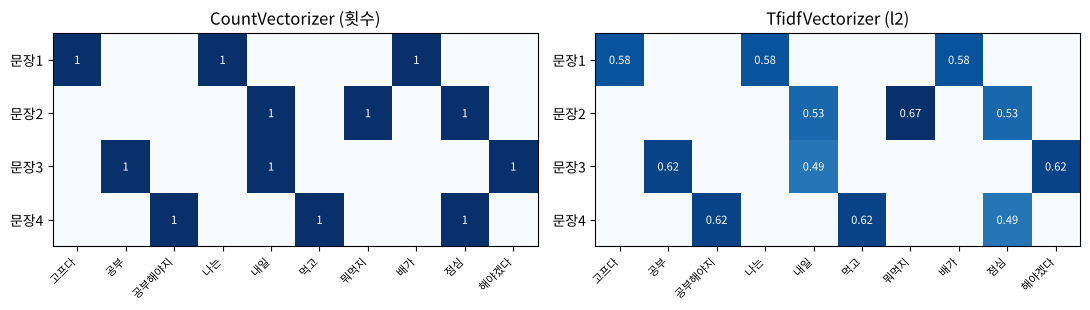

0 인 칸 비율 : 70%  (문장 4개 · 사전 10개)


In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, M, name in zip(axes, [tf, X.toarray()], ['CountVectorizer (횟수)', 'TfidfVectorizer (l2)']):
    im = ax.imshow(M, cmap='Blues', aspect='auto')
    ax.set_xticks(range(len(cols)), cols, rotation=45, ha='right', fontsize=8)
    ax.set_yticks(range(N), [f'문장{i+1}' for i in range(N)])
    for i in range(N):
        for j in range(len(cols)):
            if M[i, j]:
                ax.text(j, i, f'{M[i, j]:.2g}', ha='center', va='center', fontsize=8,
                        color='white' if M[i, j] > 0.6 * M.max() else 'black')
    ax.set_title(name)
plt.tight_layout(); plt.show()
print(f'0 인 칸 비율 : {(tf == 0).mean():.0%}  (문장 4개 · 사전 10개)')

## 5. 받은 정리 노트 다시 실행해 보기 — `TF-IDF_정리.md` · `예시코드_토큰화_벡터화_임베딩.md`

노트의 예시 문서 4개(`오늘 코로나 코로나 확진자` …)로 손계산(log₂, TF = 횟수 ÷ 단어 수)과 sklearn 을 비교한다.

In [14]:
import math
docs = ['오늘 코로나 코로나 확진자', '오늘 지하철 승강장 혼잡', '오늘 지하철 방역 강화', '오늘 날씨 맑음 산책']
tokens = [d.split() for d in docs]
vocab2 = sorted({w for d in tokens for w in d})

def my_tfidf(word, doc):                             # 노트 3단계 방식 (log2)
    tf_ = doc.count(word) / len(doc)
    df_ = sum(word in d for d in tokens)
    return tf_ * math.log2(len(docs) / df_)

hand = pd.DataFrame([[my_tfidf(w, d) for w in vocab2] for d in tokens], columns=vocab2)
tv = TfidfVectorizer()
sk = pd.DataFrame(tv.fit_transform(docs).toarray(), columns=tv.get_feature_names_out())
pd.concat({'손계산 (log₂)': hand.round(2), 'sklearn': sk.round(2)})

강화    날씨    맑음    방역    산책   승강장    오늘   지하철   코로나    혼잡   확진자
손계산 (log₂) 0  0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.00  1.00  0.00  0.50
           1  0.00  0.00  0.00  0.00  0.00  0.50  0.00  0.25  0.00  0.50  0.00
           2  0.50  0.00  0.00  0.50  0.00  0.00  0.00  0.25  0.00  0.00  0.00
           3  0.00  0.50  0.50  0.00  0.50  0.00  0.00  0.00  0.00  0.00  0.00
sklearn    0  0.00  0.00  0.00  0.00  0.00  0.00  0.23  0.00  0.87  0.00  0.44
           1  0.00  0.00  0.00  0.00  0.00  0.59  0.31  0.46  0.00  0.59  0.00
           2  0.59  0.00  0.00  0.59  0.00  0.00  0.31  0.46  0.00  0.00  0.00
           3  0.00  0.55  0.55  0.00  0.55  0.00  0.29  0.00  0.00  0.00  0.00

In [15]:
# 문서마다 '중요도 순위' 가 같은가?
for i in range(len(docs)):
    used = [w for w in vocab2 if w in tokens[i]]
    r1 = sorted(used, key=lambda w: -hand.loc[i, w])
    r2 = sorted(used, key=lambda w: -sk.loc[i, w])
    print(f'문서{i} 손계산 {r1}  sklearn {r2}  같음={r1 == r2}')

# 예시코드 파트 2 의 숫자들
cv2 = CountVectorizer(ngram_range=(1, 2)).fit(docs)
print('\nN-gram(1,2) 사전 크기 :', len(cv2.get_feature_names_out()), cv2.get_feature_names_out()[:6])
print('l2 길이                :', np.linalg.norm(sk.values, axis=1).round(3))
print(f'0 인 칸 비율           : {(sk.values == 0).mean():.0%}')

문서0 손계산 ['코로나', '확진자', '오늘']  sklearn ['코로나', '확진자', '오늘']  같음=True
문서1 손계산 ['승강장', '혼잡', '지하철', '오늘']  sklearn ['승강장', '혼잡', '지하철', '오늘']  같음=True
문서2 손계산 ['강화', '방역', '지하철', '오늘']  sklearn ['강화', '방역', '지하철', '오늘']  같음=True
문서3 손계산 ['날씨', '맑음', '산책', '오늘']  sklearn ['날씨', '맑음', '산책', '오늘']  같음=True

N-gram(1,2) 사전 크기 : 22 ['강화' '날씨' '날씨 맑음' '맑음' '맑음 산책' '방역']
l2 길이                : [1. 1. 1. 1.]
0 인 칸 비율           : 66%


**확인 결과** — 두 노트의 숫자(sklearn 표 `0.87 · 0.44 · 0.23` …, N-gram 22개, 0 비율 66%, 손계산 1.0 · 0.5 · 0.25)는 **모두 실행 결과와 같다.** 순위가 같다는 설명도 이 예시에서는 맞다 (값이 같은 단어끼리는 순서가 바뀔 수 있음).

> **📝 고친 부분 (`TF-IDF_정리.md` 끝 'scikit-learn 은 숫자가 조금 다르다')**
> - 빠진 차이 하나 : sklearn 의 **TF 는 횟수 그대로**다(노트처럼 문서 단어 수로 나누지 않음). 길이 영향은 마지막 **l2 정규화**가 대신 없앤다
> - '0 으로 나누는 걸 막으려고 `ln((1+N)/(1+DF)) + 1`' → 분자 · 분모의 `1+` 가 0 나눗셈을 막는 부분(smoothing)이고, 끝의 `+1` 은 **모든 문서에 나오는 단어도 0 이 되지 않게** 하는 부분이다 ('오늘' 이 0 이 아닌 이유)
> - '순위는 손계산과 같게 나온다' → **이 예시에서는** 같다. 일반적으로는 TF 를 나누는 방식 · IDF 모양이 달라 순위가 바뀔 수 있다

## 정리

| 함수 | 하는 일 |
|---|---|
| `CountVectorizer().fit(말뭉치)` | 토큰화(글자 2개 이상 · 소문자) → 단어 사전 `vocabulary_` |
| `.transform(문장들)` | 희소 행렬 (문장 수 × 사전 크기), 값 = 횟수 |
| `TfidfVectorizer().fit(말뭉치)` | 단어 사전 + `idf_` 학습 |
| `.transform(문장들)` | TF × IDF → 문장마다 길이 1 (`norm='l2'`) |

다음 : 이렇게 만든 벡터 두 개가 얼마나 비슷한지 — **코사인 유사도** → [`text_similarity_cosine.ipynb`](./text_similarity_cosine.ipynb)